# Trabajo Final - Fundamentos y Algoritmia para IA
Dataset: Seeds (3 variedades de trigo, 7 características)

In [1]:
%pip install -q numpy pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

## Carga y exploración del dataset con Pandas

In [3]:
import io, zipfile, urllib.request

nombres_cols = ["Area", "Perimeter", "Compactness", "Kernel_Length",
                "Kernel_Width", "Asymmetry_Coef", "Groove_Length"]

def cargar_seeds():
    # Opción 1: OpenML (dataset Seeds, id 1499)
    try:
        from sklearn.datasets import fetch_openml
        d = fetch_openml(data_id=1499, as_frame=True)
        datos = d.data.copy()
        datos.columns = nombres_cols
        datos["Class"] = d.target.astype(float).astype(int).values
        return datos
    except Exception as e:
        print("OpenML falló, probando UCI directo...", e)
    # Opción 2: archivo original de UCI
    url = "https://archive.ics.uci.edu/static/public/236/seeds.zip"
    with urllib.request.urlopen(url) as r:
        z = zipfile.ZipFile(io.BytesIO(r.read()))
    nombre = [n for n in z.namelist() if n.endswith(".txt")][0]
    datos = pd.read_csv(z.open(nombre), sep=r"\s+", header=None)
    datos.columns = nombres_cols + ["Class"]
    datos["Class"] = datos["Class"].astype(int)
    return datos

df = cargar_seeds()

print("Forma del dataset:", df.shape)
df.head()

Forma del dataset: (210, 8)


,Area,Perimeter,Compactness,Kernel_Length,Kernel_Width,Asymmetry_Coef,Groove_Length,Class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [4]:
print("Características:", list(df.columns[:-1]))
print("Cantidad de características:", len(df.columns) - 1)
print("\n--- Info ---")
df.info()
print("\n--- Valores nulos por columna ---")
print(df.isnull().sum())
print("\n--- Muestras por clase ---")
print(df["Class"].value_counts())
df.describe()

Características: ['Area', 'Perimeter', 'Compactness', 'Kernel_Length', 'Kernel_Width', 'Asymmetry_Coef', 'Groove_Length']
Cantidad de características: 7

--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Area            210 non-null    float64
 1   Perimeter       210 non-null    float64
 2   Compactness     210 non-null    float64
 3   Kernel_Length   210 non-null    float64
 4   Kernel_Width    210 non-null    float64
 5   Asymmetry_Coef  210 non-null    float64
 6   Groove_Length   210 non-null    float64
 7   Class           210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB

--- Valores nulos por columna ---
Area              0
Perimeter         0
Compactness       0
Kernel_Length     0
Kernel_Width      0
Asymmetry_Coef    0
Groove_Length     0
Class             0
dtype: int64

--- Muestras por clase ---
Cla

,Area,Perimeter,Compactness,Kernel_Length,Kernel_Width,Asymmetry_Coef,Groove_Length,Class
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000


## Separar predictoras y variable Class + normalización (StandardScaler)

In [5]:
x = df.drop("Class", axis=1)   # características predictoras
y = df["Class"]                # variable objetivo

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
x_train_sc = scaler.fit_transform(x_train)  # se ajusta solo con entrenamiento
x_test_sc = scaler.transform(x_test)

print("Entrenamiento:", x_train_sc.shape, "| Prueba:", x_test_sc.shape)
print("Media (train) tras escalar:", x_train_sc.mean(axis=0).round(2))
print("Desv. est. (train) tras escalar:", x_train_sc.std(axis=0).round(2))

Entrenamiento: (168, 7) | Prueba: (42, 7)
Media (train) tras escalar: [-0. -0.  0.  0. -0.  0.  0.]
Desv. est. (train) tras escalar: [1. 1. 1. 1. 1. 1. 1.]


## Álgebra lineal con NumPy

In [6]:
# Vectores (dos muestras: Area, Perimeter, Compactness)
v1 = np.array([15.26, 14.84, 0.871])
v2 = np.array([14.88, 14.57, 0.881])

# Matrices
A = np.array([[2, 1],
              [1, 3]])
B = np.array([[1, 0],
              [4, 2]])

print("v1:", v1, "| v2:", v2)
print("Matriz A:\n", A)
print("Matriz B:\n", B)
print("A + B:\n", A + B)
print("A x B:\n", A @ B)
print("Transpuesta de A:\n", A.T)

# Producto punto y norma
print("\nProducto punto v1 . v2:", np.dot(v1, v2))
print("Norma de v1:", np.linalg.norm(v1))
print("Norma de v2:", np.linalg.norm(v2))

# Sistema de ecuaciones:  2x + y = 5  ;  x + 3y = 10
b = np.array([5, 10])
sol = np.linalg.solve(A, b)
print("\nSolución del sistema (x, y):", sol)
print("Verificación A @ sol:", A @ sol)

v1: [15.26  14.84   0.871] | v2: [14.88  14.57   0.881]
Matriz A:
 [[2 1]
 [1 3]]
Matriz B:
 [[1 0]
 [4 2]]
A + B:
 [[3 1]
 [5 5]]
A x B:
 [[ 6  2]
 [13  6]]
Transpuesta de A:
 [[2 1]
 [1 3]]

Producto punto v1 . v2: 444.054951
Norma de v1: 21.30379874576363
Norma de v2: 20.84407496148486

Solución del sistema (x, y): [1. 3.]
Verificación A @ sol: [ 5. 10.]


## Media, mediana, varianza y desviación estándar (Area y Perimeter)

In [7]:
def varianza_manual(datos, ddof=1):
    datos = np.array(datos)
    n = len(datos)
    media = sum(datos) / n
    suma_cuadrados = sum((d - media) ** 2 for d in datos)
    return suma_cuadrados / (n - ddof)

def desviacion_manual(datos, ddof=1):
    return varianza_manual(datos, ddof) ** 0.5

for col in ["Area", "Perimeter"]:
    print(f"--------- {col} ---------")
    print(f"Media: {df[col].mean():.4f}")
    print(f"Mediana: {df[col].median():.4f}")
    print(f"Varianza muestral (NumPy): {np.var(df[col], ddof=1):.4f}")
    print(f"Desviación estándar (NumPy): {np.std(df[col], ddof=1):.4f}")

area = df["Area"].values
var_m = varianza_manual(area)
std_m = desviacion_manual(area)
var_np = np.var(area, ddof=1)
std_np = np.std(area, ddof=1)

print("\n===== Comparación manual vs NumPy (Area) =====")
print(f"Varianza  -> manual: {var_m:.6f} | NumPy: {var_np:.6f}")
print(f"Desv. est -> manual: {std_m:.6f} | NumPy: {std_np:.6f}")
print("¿Coinciden?:", np.isclose(var_m, var_np) and np.isclose(std_m, std_np))

--------- Area ---------
Media: 14.8475
Mediana: 14.3550
Varianza muestral (NumPy): 8.4664
Desviación estándar (NumPy): 2.9097
--------- Perimeter ---------
Media: 14.5593
Mediana: 14.3200
Varianza muestral (NumPy): 1.7055
Desviación estándar (NumPy): 1.3060

===== Comparación manual vs NumPy (Area) =====
Varianza  -> manual: 8.466351 | NumPy: 8.466351
Desv. est -> manual: 2.909699 | NumPy: 2.909699
¿Coinciden?: True


## Valores atípicos en Area (criterio de 2 desviaciones estándar)

In [8]:
media_area = df["Area"].mean()
std_area = df["Area"].std()
limite_inf = media_area - 2 * std_area
limite_sup = media_area + 2 * std_area

print(f"Límite inferior: {limite_inf:.4f}")
print(f"Límite superior: {limite_sup:.4f}")

atipicos = df[(df["Area"] < limite_inf) | (df["Area"] > limite_sup)]
print("Cantidad de valores atípicos:", len(atipicos))
atipicos[["Area", "Perimeter", "Class"]]

Límite inferior: 9.0281
Límite superior: 20.6669
Cantidad de valores atípicos: 4


,Area,Perimeter,Class
77,20.71,17.23,2
88,21.18,17.21,2
89,20.88,17.05,2
114,20.97,17.25,2


## Gráficos: histograma de Area y dispersión Area vs Perimeter

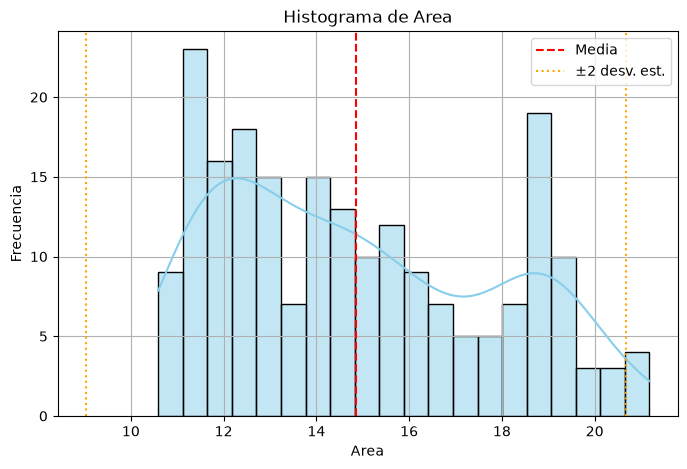

In [9]:
nombres = {1: "Kama", 2: "Rosa", 3: "Canadian"}
df["Variedad"] = df["Class"].map(nombres)

plt.figure(figsize=(8, 5))
sns.histplot(df["Area"], bins=20, kde=True, color="skyblue", edgecolor="black")
plt.axvline(media_area, color="red", linestyle="--", label="Media")
plt.axvline(limite_inf, color="orange", linestyle=":", label="±2 desv. est.")
plt.axvline(limite_sup, color="orange", linestyle=":")
plt.title("Histograma de Area")
plt.xlabel("Area")
plt.ylabel("Frecuencia")
plt.legend()
plt.grid()
plt.show()

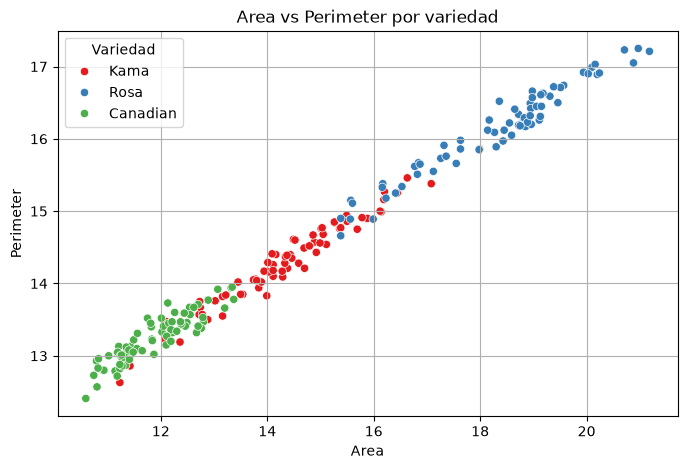

In [10]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Area", y="Perimeter", hue="Variedad", palette="Set1")
plt.title("Area vs Perimeter por variedad")
plt.grid()
plt.show()

## Entrenamiento y comparación: K-Vecinos vs Árbol de Decisión

-----Comparación de Métricas-----
Accuracy KNeighborsClassifier: 0.9048
Accuracy DecisionTreeClassifier: 0.8810

Reporte KNN
               precision    recall  f1-score   support

           1       1.00      0.71      0.83        14
           2       0.88      1.00      0.93        14
           3       0.88      1.00      0.93        14

    accuracy                           0.90        42
   macro avg       0.92      0.90      0.90        42
weighted avg       0.92      0.90      0.90        42

Reporte Árbol de Decisión
               precision    recall  f1-score   support

           1       0.91      0.71      0.80        14
           2       0.87      0.93      0.90        14
           3       0.88      1.00      0.93        14

    accuracy                           0.88        42
   macro avg       0.88      0.88      0.88        42
weighted avg       0.88      0.88      0.88        42



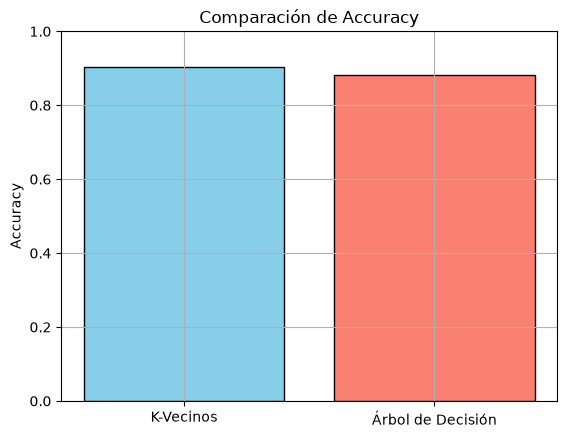

In [11]:
# K-Vecinos (usa datos normalizados)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train_sc, y_train)
y_pred_knn = knn.predict(x_test_sc)
acc_knn = accuracy_score(y_test, y_pred_knn)

# Árbol de Decisión
tree = DecisionTreeClassifier(random_state=42)
tree.fit(x_train_sc, y_train)
y_pred_tree = tree.predict(x_test_sc)
acc_tree = accuracy_score(y_test, y_pred_tree)

print("-----Comparación de Métricas-----")
print(f"Accuracy KNeighborsClassifier: {acc_knn:.4f}")
print(f"Accuracy DecisionTreeClassifier: {acc_tree:.4f}")
print("\nReporte KNN\n", classification_report(y_test, y_pred_knn))
print("Reporte Árbol de Decisión\n", classification_report(y_test, y_pred_tree))

plt.bar(["K-Vecinos", "Árbol de Decisión"], [acc_knn, acc_tree],
        color=["skyblue", "salmon"], edgecolor="black")
plt.title("Comparación de Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid()
plt.show()